# 09 — Ripple information (`EXP-H07`)

## 1. Objective
Test whether exchange-time trade flow improves short-horizon return densities and target-before-stop probabilities after a frozen slow state. This is an information test. It does not authorise exposure and it does not score execution.

## 2. Hypothesis
At each closed minute, trade flow known from prints at or before that minute improves the 5-, 15-, and 60-minute conditional log-return density and the target-before-stop probability. The slow state is the trailing 60-minute log return and the trailing 60-minute log volatility. The flow state is aggressor-signed volume over 60 seconds, trade count over 60 seconds, and aggressor-signed volume over 5 minutes. An aggressor buy is a trade that is not buyer-maker.

## 3. Null
Trade flow does not improve mean log score and Brier score at every horizon. One horizon or one endpoint cannot reject the null.

## 4. Information set
The decision clock is the closed minute. The slow state uses the closed 1-minute bar at that minute. Trade flow uses exchange timestamps at or before that minute. The stored tape has no receipt timestamp, so this development run cannot prove that a print had arrived locally. Depth diffs are not in the information set. H2, H4, and H5 are not treated as retained.

## 5. Dataset
`btcusdt-l2-trades`, the prospective BTCUSDT trade objects under `ticks-parquet/` and `ticks/`. The 1-minute bars supply only the slow state. Their scores are not an H7 result. Depth-update objects are counted and not downloaded.

## 6. Data quality
Exact duplicate prints and non-positive prices or quantities are counted and removed. Out-of-order prints are counted and sorted. A horizon with a gap above 60 seconds is excluded and counted. Decisions with no trade in the prior 60 seconds are excluded and counted. Unreadable objects are quarantined and left out of the digest.

## 7. Labels
The horizon log return is the last trade price at or before the horizon end, minus the log entry price. The entry price is the last print at or before the decision. Target-before-stop is 1 when the upper barrier is printed first and 0 otherwise. Barrier width is the causal 60-minute volatility times the square root of the horizon. The path is the trade tape. A gap inside the horizon drops the label.

## 8. Baseline
The nested model is `wave_tide`: a Student-t conditional density and a logistic target-before-stop probability using only the slow state. Student-t is the working residual family. It is not a claim that H1 has been confirmed.

## 9. Model family
The candidate is `trade_flow`, the same two estimators with the slow state and the three trade-flow features. Snapshot spread, imbalance, and microprice are an ablation. They are not in the primary comparison. A continuous book is not reconstructed.

## 10. Splits
Score only when the tape covers at least 35 calendar days. The development windows are 14 training days and 7 validation days, stepping by 7 days. The final 14 days are unread. That tail is a development holdout, not H7 confirmation.

## 11. Configuration
The source of truth is `research.protocol.H7_CONFIG`. Confirmation refuses while the archive has one clock and no depth sequence ids.

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
import logging
_log = logging.getLogger()
_log.setLevel(logging.INFO)
_log.addHandler(logging.FileHandler("/tmp/h7-ripple-run.log", mode="w"))
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.protocol import H7_CONFIG
from research.registry import config_digest, load_record

EXPERIMENT_ID = "EXP-H07"
CONFIG = dict(H7_CONFIG)
RECORD_PATH = root / "research" / "registry" / "EXP-H07.json"
MANIFEST_PATH = root / "research" / "registry" / "datasets" / "btcusdt-l2-trades.json"
BAR_MANIFEST_PATH = root / "research" / "registry" / "datasets" / "btcusdt-1m.json"
record = load_record(RECORD_PATH)
print("experiment:", record.experiment_id, record.status)
print("config_digest:", config_digest(CONFIG))

experiment: EXP-H07 Deferred
config_digest: efd0fa5e7e2f3d8d67beeb80b546f12c0ba30236917f4445a946ede7a6895a1c


## 5–6. Dataset and data quality

List both stored trade layouts. Download trade prints only. Count depth-diff objects without reading them. The frozen 1-minute manifest supplies the slow state and is not mixed into the H7 score.

In [2]:
from research.evaluate import align_to_frozen_dataset
from research.load import list_h7_depth_inventory, list_h7_trade_objects, load_research_bars, load_trade_tape
from research.manifest import QualityExclusions, build_manifest, load_manifest, save_manifest
from research.report import quality_table, ripple_quality_table
from research.ripple import normalise_trades

trade_objects = list_h7_trade_objects(CONFIG)
depth_objects, depth_bytes = list_h7_depth_inventory(CONFIG)
trades, readable_objects, unreadable_objects = load_trade_tape(
    trade_objects,
    bucket=CONFIG["bucket"],
    profile=CONFIG["profile"],
)
clean_trades, _, _, _ = normalise_trades(trades)
if clean_trades.empty:
    raise RuntimeError("trade quarantine removed every print")
bar_manifest = load_manifest(BAR_MANIFEST_PATH)
loaded_bars, bar_objects = load_research_bars(
    venue=CONFIG["venue"],
    symbol=CONFIG["symbol"],
    timeframe="1m",
    bucket=CONFIG["bucket"],
    profile=CONFIG["profile"],
    region=CONFIG["region"],
)
bars, bar_quality, collector_rows_after_freeze = align_to_frozen_dataset(
    loaded_bars, bar_manifest, bar_objects
)
print("trade_objects:", len(readable_objects))
print("unreadable_trade_objects:", unreadable_objects)
print("depth_update_objects:", depth_objects)
print("depth_update_bytes:", depth_bytes)
print("trade_window:", clean_trades.index.min().isoformat(), "to", clean_trades.index.max().isoformat())
print("bar conditioning digest:", bar_manifest.digest)
print("bar collector rows after freeze:", collector_rows_after_freeze)
display(quality_table({CONFIG["symbol"]: bar_quality}))

trade_objects: 99299
unreadable_trade_objects: 0
depth_update_objects: 99506
depth_update_bytes: 15283640651
trade_window: 2026-07-20T00:20:55.992000+00:00 to 2026-11-02T10:39:32.701000+00:00
bar conditioning digest: d67871b2eebd796cb37c7cafa89677fbca4b31ad0bdae959a5f0e2efeecc6c88
bar collector rows after freeze: 10345


         rows_in  rows_kept  duplicate_timestamps  off_grid_timestamps  nonpositive_prices  inconsistent_ohlc  missing_minutes  largest_gap_minutes
series                                                                                                                                             
BTCUSDT  3585983    3585983                     0                    0                   0                  0                0                    1

## 12–17. Evaluation

12. Statistical evaluation: mean log score of the conditional return density, and Brier score of target-before-stop. Both must improve at 5, 15, and 60 minutes.
13. Economic evaluation: none. H7 is predictive only. Execution value is H8.
14. Calibration: the conditional density reports a PIT and a VaR coverage probability. The binary model reports Brier score. Neither is a trading rule.
15. Ablation: `trade_flow` versus `wave_tide` on the same decisions. Snapshot books are counted separately and do not enter the fit.
16. Robustness: a calendar step with fewer than 30 train or validation labels is counted and not registered. Every registered origin and horizon must finish. The final 14 days stay unread.
17. Failure analysis: short coverage, failed origins, horizon gaps, feature exclusions, and unreadable objects stay visible. A failed Student-t moment match does not fall back to a Gaussian.

In [3]:
from research.evaluate import evaluate_h7

evaluation = evaluate_h7(
    bars,
    trades,
    CONFIG,
    depth_update_objects=depth_objects,
    depth_update_bytes=depth_bytes,
    unreadable_objects=unreadable_objects,
)
trade_manifest = build_manifest(
    dataset_id=CONFIG["dataset_id"],
    venue=CONFIG["venue"],
    symbol=CONFIG["symbol"],
    timeframe=CONFIG["timeframe"],
    bucket=CONFIG["bucket"],
    profile=CONFIG["profile"],
    objects=readable_objects,
    start=clean_trades.index.min().isoformat(),
    end=clean_trades.index.max().isoformat(),
    exclusions=QualityExclusions(
        duplicate_timestamps=evaluation.quality.duplicate_rows,
        nonpositive_prices=evaluation.quality.nonpositive_rows,
    ),
    schema_version="trades-v1",
)
save_manifest(MANIFEST_PATH, trade_manifest)
print("dataset_id:", trade_manifest.dataset_id)
print("dataset_digest:", trade_manifest.digest)
print("deferred:", evaluation.deferred)
print("defer_reason:", evaluation.defer_reason or "none")
print("sealed_boundary:", None if evaluation.boundary is None else evaluation.boundary.isoformat())
print("failures:", len(evaluation.failures))
print("skipped_sparse_origins:", len(evaluation.skipped_origins))
print("snapshot_matched:", evaluation.snapshot_matched)
print("snapshot_identified:", evaluation.snapshot_identified)
display(ripple_quality_table(evaluation.quality))
if evaluation.failures:
    display(pd.DataFrame(evaluation.failures))

dataset_id: btcusdt-l2-trades
dataset_digest: e5d6d33828b8b10c963b863b1d39f596c8470765d9e8cb8ada2a0304bb4a3cc4
deferred: False
defer_reason: none
sealed_boundary: 2026-10-12T06:22:00+00:00
failures: 0
skipped_sparse_origins: 8
snapshot_matched: 0
snapshot_identified: False


          rows_in  rows_kept  duplicate_rows  nonpositive_rows  coverage_days  decisions  feature_exclusions  gap_exclusions  endpoint_exclusions  labels  depth_update_objects  depth_update_bytes  unreadable_objects    clocks  depth_sequence_ids
item                                                                                                                                                                                                                                                 
trades  120872511   87070682        33362006            439823             46      50865             3535058               0                    0       0                 99506         15283640651                   0  exchange               False
5m      120872511   87070682        33362006            439823             46      50865             3535058             390                    0   50475                 99506         15283640651                   0  exchange               False
15m     12087251

## How to read the scores

A positive advantage means trade flow beat the slow state. Log score is higher-better. Brier score is lower-better, and the table already flips it so that positive remains an improvement. The snapshot ablation is not in this table.

   horizon_minutes   endpoint  mean_advantage  origins  expected_origins
0                5      brier      0.00141723        2                 2
1               15      brier     0.000845513        2                 2
2               60      brier     0.000418791        2                 2
3                5  log_score      0.00381231        2                 2
4               15  log_score     -0.00126459        2                 2
5               60  log_score      -0.0082952        2                 2

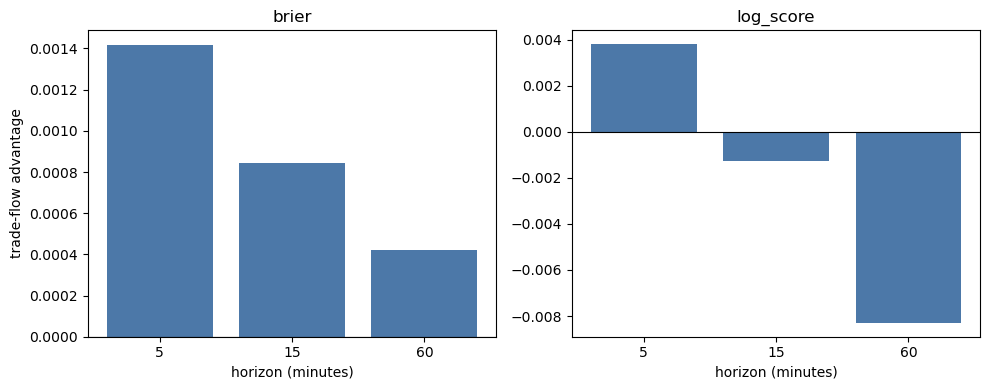

<Figure>

In [4]:
from research.report import plot_ripple_advantage, ripple_comparison_table

if evaluation.deferred or evaluation.comparison.empty:
    print("No development comparison was scored.")
else:
    display(ripple_comparison_table(evaluation.comparison))
    display(plot_ripple_advantage(evaluation.comparison))

## 18. Result

This cell states the development answer only. It does not retain a feature and it does not read the unread tail as confirmation.

In [5]:
from research.evaluate import h7_development_decision

verdict = h7_development_decision(evaluation).iloc[0]
if verdict.null_decision == "reject":
    print("Answer: yes on development data; trade flow passes the registered gate.")
elif verdict.null_decision == "accept":
    print("Answer: no; the slow state remains the working forecast.")
else:
    print("Answer: not yet; H7 is deferred.")
print("Why:", verdict.reason)
print("This is development evidence. The unread tail has not been used as confirmation.")

Answer: no; the slow state remains the working forecast.
Why: Trade flow does not improve both log score and Brier score at every horizon
This is development evidence. The unread tail has not been used as confirmation.


## 19. Decision

Record the development result without a sealed retain or reject. The registry is the lifecycle authority. Confirmation stays closed because receipt time and depth sequence ids were not stored.

In [6]:
from research.evaluate import h7_confirmation_blockers
from research.report import record_development_decision

updated_record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=trade_manifest.dataset_id,
    dataset_digest=trade_manifest.digest,
    config=CONFIG,
    root=root,
)
display(asdict(updated_record))
blockers = h7_confirmation_blockers(root=root, record=updated_record)
print("confirmation_blockers:")
for blocker in blockers:
    print("-", blocker)

confirmation_blockers:
- the research code is uncommitted (53df8883077c46048647a4e3a1a88f5d333bded6+dirty)
- the stored trade tape has an exchange timestamp and no receipt timestamp
- depth sequence ids are absent, so books are not reconstructed


{'experiment_id': 'EXP-H07', 'hypothesis': 'Trade-flow state known at the minute close improves 5-, 15-, and 60-minute conditional return densities and target-before-stop probabilities after a frozen trailing-return and trailing-volatility state.', 'null': 'Trade-flow state does not improve mean log score and Brier score at every horizon relative to that frozen slow state.', 'parent_hypothesis': None, 'dataset_id': 'btcusdt-l2-trades', 'dataset_digest': 'e5d6d33828b8b10c963b863b1d39f596c8470765d9e8cb8ada2a0304bb4a3cc4', 'code_version': '53df8883077c46048647a4e3a1a88f5d333bded6+dirty', 'config_digest': 'efd0fa5e7e2f3d8d67beeb80b546f12c0ba30236917f4445a946ede7a6895a1c', 'status': 'Exploratory', 'result': 'wave_tide', 'decision': '', 'component': 'research.ripple', 'notebook': 'notebooks/research/09_ripple_information.ipynb', 'horizons': (5, 15, 60), 'sealed_access': False, 'run_id': ''}

## Sealed confirmation

Leave disabled. `confirm_h7` refuses on this archive even if the flag is turned on.

In [7]:
from research.evaluate import confirm_h7

RUN_SEALED_CONFIRMATION = False
if RUN_SEALED_CONFIRMATION:
    confirm_h7(config=CONFIG)
else:
    print("sealed confirmation disabled")

sealed confirmation disabled


## 20. Reusable implementation extracted

`research.ripple` contains the exchange-time trade-flow features, the trade-path labels, the gap counts, and the snapshot ablation that refuses depth diffs. `research.evaluate.evaluate_h7` owns the day windows and the development decision. `confirm_h7` refuses retention until a receipt timestamp and depth sequence ids exist.

## 21. Next experiment

H8 (`10_execution_baselines`, `EXP-H08`) compares fixed execution policies on a frozen parent decision. It does not reuse this information result as a trading edge.